# S30 - Unidad 2. Evidencia de Aprendizaje 3 - Aprendizaje supervisado y no supervisado

# Integrantes

Natalia Jadith Castro Ospino

Oscar Luis Maqruez Arrieta


# 0. Pregunta de negocio y construcción automática del DataFrame

# Pregunta de Negocio

¿Es posible identificar el estilo de consumo de los clientes teniendo en cuenta su ubicación geográfica y el valor de su cuota mensual?

# A quien beneficia?

Podriamos decir que la respuesta a esta pregunta beneficiaria a empresas que ofrecen algun servicio de suscripción o plataforma de netretenimiento. Esta tendria como objetivo tener en cuenta los datos de los clientes sobre su hubicacion geografica y dependiendo de su posicion organizar el valor de su cuota mensual de suscripción.

# Que desición apoya?

Permite conocer los diferentes estilos de consumo de los clientes y apoyar la creación de planes, promociones y estrategias de fidelización.

# Dataset seleccionado
   
- Nombre: Customer Profile.
  
- Identificador: hpestrellag/customer_profile.
  
- Plataforma: Hugging Face.
  
- Formato: CSV.
  
- Split: train.
  
- Cantidad de registros: 500.000.
  
- Licencia: CC BY-NC 4.0.
  
Enlace: https://huggingface.co/datasets/hpestrellag/customer_profile

# Columnas relevantes

Columna	 ------------->            Descripción

customer_id	   ------------>      Identificador del cliente.

department	 --------->         Departamento o subdivisión.

consumption_style	--------->  Estilo de consumo.

locality	------------>          Localidad del cliente.

province	----------->          Provincia del cliente.

monthly_fee_usd	--------->      Cuota mensual en dólares.


# ¿Por qué escogimos este dataset?

Escogimos este dataset porque contiene información sobre la ubicación de los clientes, el valor de su cuota mensual y sus diferentes estilos de consumo.

Estas características permiten plantear un problema de clasificación para identificar el estilo de consumo de los clientes.

# Importamos la clase de carga

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases.hf_loader import HFDatasetLoader

/workspaces/Projects_Machine_Learning2026_S10---EA1/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configuramos el dataset

loader = HFDatasetLoader(
    dataset_name="hpestrellag/customer_profile",
    split="train",
    filename="datos/hpestrellag/customer_profile.csv",
)

In [3]:
# Descargamos y cargamos

df = loader.load()
df.head(10)

,customer_id,department,consumption_style,locality,province,monthly_fee_usd
0,SLX83969,department_cat_153,heavy-user,locality_cat_163,Misiones,9.12
1,UTT27594,department_cat_1,occasional,locality_cat_268,Tucumán,10.15
2,HER11355,department_cat_1,occasional,locality_cat_102,Buenos Aires,18.93
3,ZRQ19908,department_cat_142,weekend-viewer,locality_cat_29,Santiago del Estero,7.36
4,EAT08840,department_cat_142,occasional,locality_cat_90,Córdoba,7.56
5,KYJ36841,department_cat_1,occasional,locality_cat_1,Santiago del Estero,8.31
6,FWX15967,department_cat_120,occasional,locality_cat_335,Santa Fe,8.07
7,YFL75558,department_cat_131,weekend-viewer,locality_cat_630,Buenos Aires,9.77
8,SYQ06673,department_cat_1,occasional,locality_cat_658,Córdoba,11.06
9,ULR53254,department_cat_112,weekend-viewer,locality_cat_445,Córdoba,11.55


# 1. Evidencia de preprocesamiento

In [4]:
# Tamaño del dataset

print("Tamaño del DataFrame:", df.shape)

Tamaño del DataFrame: (500000, 6)


In [5]:
# Tipo de datos
print("Tipos de datos:")

print(df.dtypes)

Tipos de datos:
customer_id              str
department               str
consumption_style        str
locality                 str
province                 str
monthly_fee_usd      float64
dtype: object


In [6]:
# Revisamos que valores nulos existes

print("\nValores nulos:")
print(df.isnull().sum())


Valores nulos:
customer_id          0
department           0
consumption_style    0
locality             0
province             0
monthly_fee_usd      0
dtype: int64


In [7]:
# En esta parte revisamos que registros estan duplicados

print("\nRegistros duplicados:", df.duplicated().sum())


Registros duplicados: 0


Revisamos que nuestro dataset esta completamente limpio desde el inicio. Se revisaron los valores nulos y los registros duplicados del dataset. Los resultados mostraron que no existen valores faltantes ni registros repetidos, por lo que no fue necesario aplicar operaciones de eliminación o imputación.

In [8]:
#  las variables predictoras
X = df[[
    "department",
    "locality",
    "province",
    "monthly_fee_usd"
]]

#variable objetivo
y = df["consumption_style"]

# Mostrar las variables
print("Variables predictoras:")
display(X.head())

print("\nVariable objetivo:")
display(y.head())

Variables predictoras:


,department,locality,province,monthly_fee_usd
0,department_cat_153,locality_cat_163,Misiones,9.12
1,department_cat_1,locality_cat_268,Tucumán,10.15
2,department_cat_1,locality_cat_102,Buenos Aires,18.93
3,department_cat_142,locality_cat_29,Santiago del Estero,7.36
4,department_cat_142,locality_cat_90,Córdoba,7.56



Variable objetivo:


0        heavy-user
1        occasional
2        occasional
3    weekend-viewer
4        occasional
Name: consumption_style, dtype: str

In [9]:
# Informacion General
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   customer_id        500000 non-null  str    
 1   department         500000 non-null  str    
 2   consumption_style  500000 non-null  str    
 3   locality           500000 non-null  str    
 4   province           500000 non-null  str    
 5   monthly_fee_usd    500000 non-null  float64
dtypes: float64(1), str(5)
memory usage: 51.7 MB


In [10]:
# Categorias

# categorías de consumo
print("Estilos de consumo:")
print(df["consumption_style"].value_counts())

# categorías de ubicación
print("\nDepartamentos:")
print(df["department"].nunique())

print("\nLocalidades:")
print(df["locality"].nunique())

print("\nProvincias:")
print(df["province"].nunique())

Estilos de consumo:
consumption_style
occasional        288181
casual             98581
weekend-viewer     73431
binge-watcher      26248
heavy-user         13559
Name: count, dtype: int64

Departamentos:
196

Localidades:
679

Provincias:
23


# Separamos datos de entrenamiestos y pruebas

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (400000, 4)
Datos de prueba: (100000, 4)


In [12]:
# Covertir categorias ya que random Forest trabaja con Valores numericos

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

#  columnas categóricas
columnas_categoricas = [
    "department",
    "locality",
    "province"
]

# preprarar transformación
preprocesador = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(handle_unknown="ignore"),
         columnas_categoricas)
    ],
    remainder="passthrough"
)

# Ajustar con entrenamiento y transformar
X_train_procesado = preprocesador.fit_transform(X_train)

# Transformar los datos de prueba
X_test_procesado = preprocesador.transform(X_test)

print("Entrenamiento procesado:", X_train_procesado.shape)
print("Prueba procesada:", X_test_procesado.shape)

Entrenamiento procesado: (400000, 891)
Prueba procesada: (100000, 891)


# 2. Selección y funcionamiento del modelo

## Modelo seleccionado


Random Forest

Tipo de aprendisaje: Supervisado



Se seleccionó el algoritmo Random Forest porque permite clasificar a los clientes según su estilo de consumo, utilizando características como su 

ubicación geográfica y el valor de su cuota mensual.

## Tipo de aprendizaje

Nuestro proyecto utiliza aprendizaje supervisado porque contamos con una variable que ya contiene la respuesta que queremos predecir.

El modelo aprenderá a partir de los datos de los clientes y utilizará esa información para predecir el estilo de consumo de nuevos registros.

## Variables del modelo

Utilizaremos las siguientes variables:

#### Tipo-----------------Variable----------------------Descripción

Predictora (X)------------department--------------------Departamento del cliente.

Predictora (X)------------locality----------------------Localidad del cliente.

Predictora (X)------------province----------------------Provincia del cliente.

Predictora (X)------------monthly_fee_usd---------------Cuota mensual en dólares.

Objetivo (Y)--------------consumption_style-------------Estilo de consumo del cliente.

La variable objetivo es consumption_style, porque representa la categoría que queremos que el modelo aprenda a identificar.

Para conocer las clases reales que utilizará el modelo, ejecuta esta celda:

In [13]:
# Mostrar las clases de la variable objetivo
print("Clases de consumo:")
print(y.value_counts())

print("\nCantidad de clases:")
print(y.nunique())

Clases de consumo:
consumption_style
occasional        288181
casual             98581
weekend-viewer     73431
binge-watcher      26248
heavy-user         13559
Name: count, dtype: int64

Cantidad de clases:
5


## Como funciona Randon Forest

Este modelo funciona mediante arboles de desicion los cuales trabajan juntos para realizar una calsificación. 

## Pasos

1. El modelo recibe los datos de los clientes.
   
3. Selecciona diferentes muestras de los datos para construir varios árboles de decisión.

5. Cada árbol aprende a clasificar los clientes utilizando diferentes características.
   
7. Cuando recibe un nuevo cliente, cada árbol realiza una predicción.
   
9. Finalmente, el modelo compara las predicciones y selecciona la categoría que obtuvo más votos.

## Parametros pricipales

#### Parámetro-------	¿Qué significa?

n_estimators------->	Cantidad de árboles que tendrá el modelo.

max_depth------->	Profundidad máxima de cada árbol.

min_samples_split------->	Cantidad mínima de registros para dividir un nodo.

min_samples_leaf------->	Cantidad mínima de registros que debe tener una hoja.

random_state------->	Permite obtener resultados reproducibles.

class_weight------->	Permite asignar mayor importancia a clases menos representadas.

## Ventajas y Limitaciones

##### Ventajas:

- Puede trabajar con problemas de clasificación de varias categorías.

- Combina varios árboles de decisión.

- No necesita escalado de las variables numéricas.

- Puede identificar relaciones entre diferentes características.

  
##### Limitaciones:

- Puede necesitar bastante memoria cuando trabaja con muchos registros.
  
- Su entrenamiento puede tardar más que el de un árbol individual.
  
- Puede ser más difícil interpretar sus resultados.
  
- Su rendimiento depende de la calidad y utilidad de las variables disponibles.

# 3. Entrenamiento, métricas y evaluación



En esta parte se entrenará un modelo de clasificación para identificar el estilo de consumo de los clientes, teniendo en cuenta su ubicación geográfica y el valor de su cuota mensual.

Para realizar esta tarea se utilizará el algoritmo Random Forest Classifier, que permite clasificar los datos mediante varios árboles de decisión.

### 3.1. Selección de variables

Para entrenar el modelo se seleccionó `consumption_style` como variable objetivo, ya que representa el estilo de consumo que queremos identificar.

Como variables predictoras se utilizaron:

- `department`: departamento del cliente.
- `locality`: localidad del cliente.
- `province`: provincia del cliente.
- `monthly_fee_usd`: valor de la cuota mensual.

Se excluyó `customer_id` porque es un identificador del cliente y no aporta información útil para realizar la clasificación.

### 3.2. Distribución de los estilos de consumo

Antes de entrenar el modelo, se revisó la cantidad de registros que tiene cada estilo de consumo.

Esto permite conocer cómo están distribuidas las categorías y comprobar si existen diferencias importantes en la cantidad de clientes de cada una.

In [14]:
df["consumption_style"].value_counts()

consumption_style
occasional        288181
casual             98581
weekend-viewer     73431
binge-watcher      26248
heavy-user         13559
Name: count, dtype: int64

### Grafico de distribución

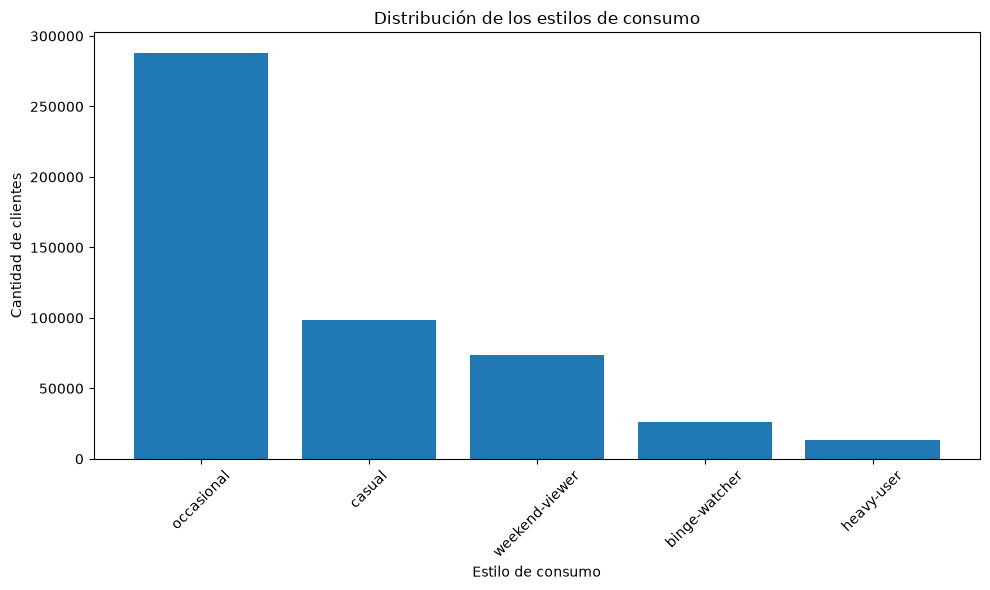

In [15]:
import matplotlib.pyplot as plt

# Contar los registros de cada estilo de consumo
distribucion = df["consumption_style"].value_counts()

# Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# Generar el gráfico de barras directamente con Matplotlib
ax.bar(
    distribucion.index,
    distribucion.values
)

# Configurar el gráfico
ax.set_title("Distribución de los estilos de consumo")
ax.set_xlabel("Estilo de consumo")
ax.set_ylabel("Cantidad de clientes")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Al revisar la distribución de los estilos de consumo, se encontró que la categoría `occasional` tiene la mayor cantidad de registros, mientras que `heavy-user` tiene la menor cantidad.

Esto indica que los datos presentan un desbalance entre las categorías. Esta situación es importante porque el modelo podría favorecer la categoría que tiene más registros y tener dificultades para identificar las demás.

### 3.3. Configuración de los hiperparámetros

Para entrenar el modelo se utilizó Random Forest Classifier con los siguientes parámetros:

- `n_estimators=30`: se utilizaron 30 árboles de decisión.
- `max_depth=12`: se estableció una profundidad máxima de 12 niveles.
- `random_state=42`: se utilizó una semilla para poder reproducir los resultados.
- `n_jobs=-1`: permite utilizar todos los procesadores disponibles.

Los demás parámetros conservaron sus valores predeterminados de Scikit-learn.

Esta configuración se utilizó inicialmente buscando mantener un tiempo de entrenamiento reducido y controlar la complejidad del modelo. Posteriormente se compararán otras configuraciones para revisar su desempeño.

### Entrenamineto del modelo

In [16]:
from sklearn.ensemble import RandomForestClassifier
import time

inicio = time.time()

modelo = RandomForestClassifier(
    n_estimators=30,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

modelo.fit(X_train_procesado, y_train)

tiempo = time.time() - inicio

print("Modelo entrenado correctamente")
print(f"Tiempo de entrenamiento: {tiempo:.2f} segundos")

Modelo entrenado correctamente
Tiempo de entrenamiento: 3.55 segundos


### 3.4. Realización de predicciones

Después de entrenar el modelo, se utilizaron los datos de prueba para realizar las predicciones.

Con esto podemos comparar los estilos de consumo que predijo el modelo con los estilos reales de los clientes.

In [17]:
predicciones = modelo.predict(X_test_procesado)

print("Predicciones por categoría:")
print(pd.Series(predicciones).value_counts())

Predicciones por categoría:
occasional    100000
Name: count, dtype: int64


### 3.5. Evaluación del modelo

Para evaluar el desempeño del modelo se utilizaron diferentes métricas:

- **Accuracy:** indica el porcentaje de predicciones correctas.
- **Precision:** indica qué tan correctas fueron las predicciones de cada categoría.
- **Recall:** muestra cuántos registros reales de cada categoría logró identificar el modelo.
- **F1-score:** combina precision y recall para evaluar el desempeño de cada categoría.

Como los datos presentan un desbalance entre los estilos de consumo, también se tendrá en cuenta el F1 macro, ya que permite evaluar todas las categorías con la misma importancia.### Calculo de mtericas

### Calculo de mtericas

In [18]:
from sklearn.metrics import accuracy_score, classification_report

exactitud = accuracy_score(y_test, predicciones)

print("Exactitud:", exactitud)

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    predicciones,
    zero_division=0
))

Exactitud: 0.57636

Reporte de clasificación:
                precision    recall  f1-score   support

 binge-watcher       0.00      0.00      0.00      5250
        casual       0.00      0.00      0.00     19716
    heavy-user       0.00      0.00      0.00      2712
    occasional       0.58      1.00      0.73     57636
weekend-viewer       0.00      0.00      0.00     14686

      accuracy                           0.58    100000
     macro avg       0.12      0.20      0.15    100000
  weighted avg       0.33      0.58      0.42    100000



###  Interpretacion de metricas

Al evaluar el modelo se obtuvo una exactitud del 57,64 % y un F1 macro del 15 %.

Aunque la exactitud puede parecer aceptable, el modelo presentó dificultades para identificar correctamente los estilos de consumo.

Esto ocurrió porque clasificó todos los registros como `occasional`, que es la categoría con mayor cantidad de clientes.

Por esta razón, las demás categorías obtuvieron valores de precision, recall y F1-score de cero.

El F1 macro permite observar mejor este problema, ya que tiene en cuenta el desempeño de todas las categorías y no solamente el de la categoría mayoritaria.

### Matriz de confusion

### 3.6. Matriz de confusión

Se utilizó una matriz de confusión para comparar las categorías reales con las predicciones realizadas por el modelo.

Esta herramienta permite observar en qué categorías el modelo está acertando y en cuáles está cometiendo errores.

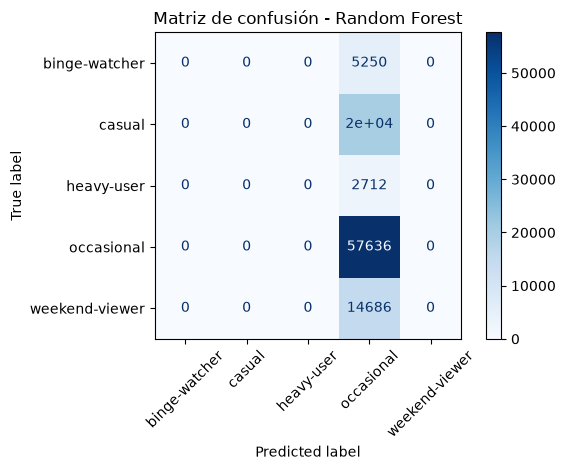

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz = confusion_matrix(
    y_test,
    predicciones,
    labels=modelo.classes_
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

visualizacion.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

La matriz de confusión muestra que el modelo clasificó todos los registros como `occasional`, incluso cuando los clientes pertenecían a otros estilos de consumo.

Esto significa que el modelo no logró diferenciar correctamente las cinco categorías.

Para el negocio, este resultado representa una limitación porque no sería posible identificar adecuadamente a los clientes según sus hábitos de consumo.

### Analisis

### 3.7. Análisis estadístico de las variables

Además de evaluar el modelo, se realizaron pruebas estadísticas para conocer si las variables utilizadas tienen alguna relación con los estilos de consumo.

Para las variables geográficas se utilizó la prueba chi-cuadrado, mientras que para la cuota mensual se utilizó la prueba ANOVA.

Se tomó como referencia un nivel de significancia de 0,05.

### Prueba chi-cuadrado

In [20]:
from scipy.stats import chi2_contingency

for columna in ["department", "locality", "province"]:

    tabla = pd.crosstab(
        df[columna],
        df["consumption_style"]
    )

    chi2, p_valor, gl, esperados = chi2_contingency(tabla)

    print(f"\nVariable: {columna}")
    print(f"Valor p: {p_valor:.6f}")

    if p_valor < 0.05:
        print("Existe asociación estadística.")
    else:
        print("No se encontró asociación estadística.")


Variable: department
Valor p: 0.705022
No se encontró asociación estadística.

Variable: locality
Valor p: 0.336713
No se encontró asociación estadística.

Variable: province
Valor p: 0.616796
No se encontró asociación estadística.


Los resultados de la prueba chi-cuadrado fueron:

- Department: 0.705022.
- Locality: 0.336713.
- Province: 0.616796.

Los tres valores p fueron superiores a 0,05. Por lo tanto, no se encontró evidencia estadística suficiente para afirmar que exista una asociación entre estas variables geográficas y los estilos de consumo.

### Prueba ANOVA

In [21]:
from scipy.stats import f_oneway

grupos = [
    grupo["monthly_fee_usd"].values
    for nombre, grupo in df.groupby("consumption_style")
]

estadistico, p_valor = f_oneway(*grupos)

print("Estadístico F:", estadistico)
print("Valor p:", p_valor)

if p_valor < 0.05:
    print("Existen diferencias significativas en la cuota mensual.")
else:
    print("No se encontraron diferencias significativas en la cuota mensual.")

Estadístico F: 1.530802648939242
Valor p: 0.1901356539851169
No se encontraron diferencias significativas en la cuota mensual.


En la prueba ANOVA se obtuvo un estadístico F de 1.5308 y un valor p de 0.1901.

Como el valor p fue superior a 0,05, no se encontraron diferencias estadísticamente significativas entre las cuotas mensuales promedio de los cinco estilos de consumo.

Este resultado indica que el valor de la cuota mensual, por sí solo, no permitió encontrar diferencias claras entre las categorías.

### 3.8. Comparación de hiperparámetros

Para revisar si la configuración inicial del modelo era adecuada, se compararon diferentes cantidades de árboles y profundidades máximas.

Se mantuvieron los mismos datos de entrenamiento y prueba y la misma semilla aleatoria para que la comparación fuera justa.

Se utilizaron las métricas Accuracy y F1 macro, dando mayor importancia al F1 macro debido al desbalance de las categorías.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time
import pandas as pd

configuraciones = [
    {"n_estimators": 30, "max_depth": 8},
    {"n_estimators": 30, "max_depth": 12},
    {"n_estimators": 50, "max_depth": 12},
    {"n_estimators": 50, "max_depth": 20}
]

resultados = []

for config in configuraciones:

    modelo_prueba = RandomForestClassifier(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        random_state=42,
        n_jobs=-1
    )

    inicio = time.time()

    modelo_prueba.fit(X_train_procesado, y_train)

    predicciones_prueba = modelo_prueba.predict(X_test_procesado)

    tiempo = time.time() - inicio

    resultados.append({
        "Arboles": config["n_estimators"],
        "Profundidad": config["max_depth"],
        "Accuracy": accuracy_score(y_test, predicciones_prueba),
        "F1 macro": f1_score(
            y_test,
            predicciones_prueba,
            average="macro",
            zero_division=0
        ),
        "Tiempo": round(tiempo, 2)
    })

comparacion = pd.DataFrame(resultados)

display(comparacion)

,Arboles,Profundidad,Accuracy,F1 macro,Tiempo
0,30,8,0.57636,0.146251,2.88
1,30,12,0.57636,0.146251,3.08
2,50,12,0.57636,0.146251,4.46
3,50,20,0.57636,0.146251,7.40


Al comparar las configuraciones se revisará cuál obtiene el mejor resultado en F1 macro y cuánto tiempo necesita para entrenarse.

Se dará prioridad al F1 macro porque permite evaluar el desempeño en las cinco categorías, evitando elegir un modelo que solamente favorezca al estilo de consumo mayoritario.

La configuración seleccionada será la que presente el mejor equilibrio entre capacidad de clasificación y tiempo de entrenamiento.

### 3.9. Evaluación frente a la pregunta de negocio

La pregunta de negocio planteada fue:

¿Es posible identificar el estilo de consumo de los clientes teniendo en cuenta su ubicación geográfica y el valor de su cuota mensual?

De acuerdo con los resultados obtenidos, no fue posible identificar adecuadamente los estilos de consumo utilizando únicamente estas variables.

Las pruebas estadísticas no encontraron asociaciones significativas entre las variables geográficas y los estilos de consumo. Tampoco se encontraron diferencias significativas en las cuotas mensuales promedio.

Además, el modelo presentó dificultades para diferenciar las cinco categorías y clasificó todos los registros como `occasional`.

Por lo tanto, las variables utilizadas no demostraron ser suficientes para realizar una clasificación confiable de los clientes.

### 3.10. Limitaciones del modelo

Durante el desarrollo del modelo se encontraron algunas limitaciones:

- Los datos presentan un desbalance entre los estilos de consumo.
- El modelo tuvo dificultades para identificar las categorías con menos registros.
- Las variables geográficas no mostraron asociaciones estadísticas significativas con el estilo de consumo.
- La cuota mensual presentó valores promedio muy similares entre las categorías.
- Las variables disponibles podrían no contener suficiente información para diferenciar los hábitos de consumo de los clientes.
- 
### Conclusión 

Se entrenó un modelo Random Forest Classifier para identificar los estilos de consumo de los clientes utilizando su ubicación geográfica y el valor de su cuota mensual.

El modelo obtuvo una exactitud del 57,64 %, pero presentó un F1 macro del 15 %, lo que demuestra dificultades para clasificar correctamente todas las categorías.

La matriz de confusión permitió observar que el modelo clasificó todos los registros como `occasional`, sin lograr reconocer los demás estilos de consumo.

Por otra parte, las pruebas estadísticas no encontraron asociaciones significativas entre las variables geográficas y el estilo de consumo, ni diferencias significativas entre las cuotas mensuales promedio.

En conclusión, con las variables disponibles y la configuración evaluada, no fue posible obtener un modelo con un desempeño suficiente para identificar confiablemente los estilos de consumo de los clientes.

# 4. Resumen automático y documento de hallazgos

Se genera un archivo de texto con la información del experimento realizado, incluyendo la pregunta de negocio, el dataset, el preprocesamiento, el algoritmo utilizado, sus parámetros y las métricas obtenidas.

In [23]:

from datetime import datetime
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


exactitud = accuracy_score(y_test, predicciones)

precision = precision_score(
    y_test, predicciones,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, predicciones,
    average="weighted",
    zero_division=0
)

f1_macro = f1_score(
    y_test, predicciones,
    average="macro",
    zero_division=0
)

f1_ponderado = f1_score(
    y_test, predicciones,
    average="weighted",
    zero_division=0
)

# Obtener parametros
parametros = modelo.get_params()

# resumen
resumen = f"""
RESUMEN DE EJECUCIÓN - PROYECTO MACHINE LEARNING

Fecha de ejecución: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

1. PREGUNTA DE NEGOCIO

¿Es posible identificar el estilo de consumo de los clientes
teniendo en cuenta su ubicación geográfica y el valor de su
cuota mensual?

2. IDENTIFICACIÓN DEL DATASET

Dataset: hpestrellag/customer_profile
Variable objetivo: consumption_style

3. PREPROCESAMIENTO

Variables predictoras:
- department
- locality
- province
- monthly_fee_usd

Variable excluida:
- customer_id

Procesamiento aplicado:
- Imputación de valores nulos mediante la moda en variables categóricas.
- Imputación mediante la mediana en variables numéricas.
- Codificación de variables categóricas mediante OneHotEncoder.
- División de datos: 80% entrenamiento y 20% prueba.
- Semilla aleatoria: 42.

Registros de entrenamiento: {len(X_train)}
Registros de prueba: {len(X_test)}

4. CONFIGURACIÓN DEL EXPERIMENTO

Tipo de aprendizaje: Supervisado - Clasificación.
Algoritmo: Random Forest Classifier.

Parámetros:
- Número de árboles: {parametros["n_estimators"]}
- Profundidad máxima: {parametros["max_depth"]}
- Semilla aleatoria: {parametros["random_state"]}
- Procesadores: {parametros["n_jobs"]}

5. MÉTRICAS DEL MODELO

Exactitud (Accuracy): {exactitud:.5f}
Precisión ponderada: {precision:.5f}
Recall ponderado: {recall:.5f}
F1 macro: {f1_macro:.5f}
F1 ponderado: {f1_ponderado:.5f}

Reporte de clasificación:

{classification_report(y_test, predicciones, zero_division=0)}

6. PREDICCIONES REALIZADAS

{pd.Series(predicciones).value_counts().to_string()}

"""

# Guardar el resumen en la carpeta de reportes
ruta_resumen = (
    ROOT / "src" / "sincronizar" / "reportes" /
    "resumen_Aprendisaje_supervisado_y_no_supervisado.txt"
)

ruta_resumen.parent.mkdir(parents=True, exist_ok=True)

with open(ruta_resumen, "w", encoding="utf-8") as archivo:
    archivo.write(resumen)

print(f"Resumen de ejecución guardado en: {ruta_resumen}")

Resumen de ejecución guardado en: /workspaces/Projects_Machine_Learning2026_S10---EA1/src/sincronizar/reportes/resumen_Aprendisaje_supervisado_y_no_supervisado.txt


### Graficas de apoyo

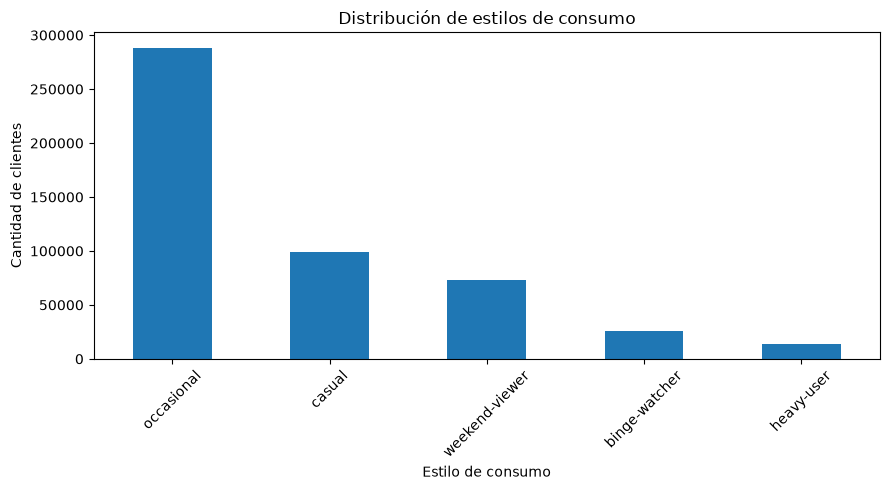

In [24]:
# Visualizar la distribución de los estilos de consumo

import matplotlib.pyplot as plt

df["consumption_style"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribución de estilos de consumo")
plt.xlabel("Estilo de consumo")
plt.ylabel("Cantidad de clientes")
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar gráfica
ruta_grafica = (
    ROOT / "src" / "sincronizar" / "reportes" /
    "distribucion_estilos.png"
)

plt.savefig(ruta_grafica, bbox_inches="tight")
plt.show()

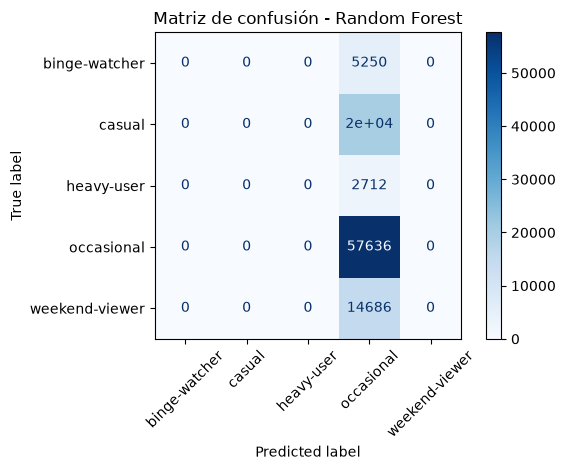

In [25]:
# Generar matriz de confusión

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(
    y_test,
    predicciones,
    labels=modelo.classes_
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

visualizacion.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()

# Guardar gráfica
ruta_matriz = (
    ROOT / "src" / "sincronizar" / "reportes" /
    "matriz_confusion.png"
)

plt.savefig(ruta_matriz, bbox_inches="tight")
plt.show()

Versión de Matplotlib: 3.11.2


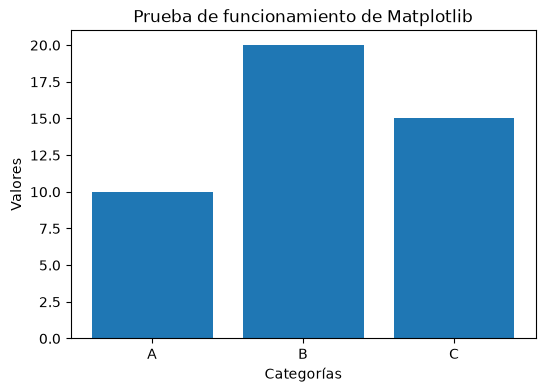

In [26]:
import matplotlib
import matplotlib.pyplot as plt

print("Versión de Matplotlib:", matplotlib.__version__)

categorias = ["A", "B", "C"]
valores = [10, 20, 15]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(categorias, valores)

ax.set_title("Prueba de funcionamiento de Matplotlib")
ax.set_xlabel("Categorías")
ax.set_ylabel("Valores")

plt.show()